# Лабораторная работа 1 — рабочий ноутбук

**ФИО:**
**Файлы данных:**

Этот ноутбук — чистовой рабочий документ, а не черновик. Он должен
исполняться сверху вниз без ошибок на выданном вам **сыром** файле
и на выходе давать очищенную таблицу и `cleaning_log.csv`.

Разделы ниже обязательны, порядок менять не нужно. Внутри раздела
добавляйте столько ячеек, сколько нужно. Если какой-то раздел у вас
пустой — напишите в нём одной строкой, почему.

## 0. Окружение и настройки

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 50)

# Пути к файлам вашего варианта S32
RAW_CLIENTS = os.path.join("data", "S32", "clients.csv")
RAW_TXN = os.path.join("data", "S32", "transactions.csv")

## 1. Загрузка сырых данных

Файлы выгружены разными системами. Убедитесь, что они прочитались
**правильно**: кодировка, разделитель, десятичный разделитель, типы,
даты, идентификаторы.

In [4]:
import csv

def detect_file_params(filepath):
    """Определяет кодировку и разделитель файла."""
    # 1. Проверяем популярные кодировки
    encodings = ['utf-8', 'windows-1251', 'cp1251', 'utf-8-sig']
    correct_enc = None
    sample_text = ""
    
    for enc in encodings:
        try:
            with open(filepath, 'r', encoding=enc) as f:
                sample_text = "".join([f.readline() for _ in range(15)])
                correct_enc = enc
                break
        except (UnicodeDecodeError, UnicodeError):
            continue
            
    # 2. Определяем разделитель колонок
    sniffer = csv.Sniffer()
    try:
        dialect = sniffer.sniff(sample_text)
        delimiter = dialect.delimiter
    except Exception:
        # Резервная эвристика, если sniffer не справился
        first_line = sample_text.split('\n')[0]
        delimiter = ';' if ';' in first_line else (',' if ',' in first_line else '\t')
        
    return correct_enc, delimiter

# Исследуем параметры файлов
clients_enc, clients_sep = detect_file_params(RAW_CLIENTS)
txn_enc, txn_sep = detect_file_params(RAW_TXN)

print(f"Параметры {RAW_CLIENTS}: кодировка={clients_enc}, разделитель='{clients_sep}'")
print(f"Параметры {RAW_TXN}: кодировка={txn_enc}, разделитель='{txn_sep}'")

# Загружаем сырые таблицы
# Пока не форсируем типы и парсинг дат, чтобы в разделе аудита увидеть исходные данные
df_clients_raw = pd.read_csv(RAW_CLIENTS, encoding=clients_enc, sep=clients_sep)
df_txn_raw = pd.read_csv(RAW_TXN, encoding=txn_enc, sep=txn_sep)

print("\n=== clients.csv: первые 3 строки ===")
display(df_clients_raw.head(3))
print(f"Размер: {df_clients_raw.shape[0]} строк, {df_clients_raw.shape[1]} колонок")

print("\n=== transactions.csv: первые 3 строки ===")
display(df_txn_raw.head(3))
print(f"Размер: {df_txn_raw.shape[0]} строк, {df_txn_raw.shape[1]} колонок")

Параметры data\S32\clients.csv: кодировка=utf-8, разделитель=','
Параметры data\S32\transactions.csv: кодировка=windows-1251, разделитель=';'

=== clients.csv: первые 3 строки ===


,client_id,birth_date,gender,city,segment,loyalty_tier,card_type,registration_date,card_open_date,income_source,monthly_income,has_mobile_app,app_last_login,satisfaction_score,branch_code,marketing_opt_in
0,C000864,1959-02-13,М,Нижний Новгород,Массовый,Серебро,Дебетовая,11.02.2021,29.07.2024,Не указан,37200.0,Да,2024-12,NaN,300,Нет
1,C000608,1980-05-27,М,Санкт-Петербург,Массовый,Серебро,Дебетовая,08.06.2012,19.05.2018,Не указан,51400.0,Да,2024-06,NaN,131,Да
2,C005220,1963-07-31,М,Санкт Петербург,Зарплатный,Золото,Дебетовая,15.02.2023,26.07.2024,Зарплата в нашем банке,115200.0,Да,2025-03,5.0,845,Нет


Размер: 5693 строк, 16 колонок

=== transactions.csv: первые 3 строки ===


,txn_id,client_id,txn_datetime,amount,currency,category,mcc_code,channel,status
0,990147,C001784,2023-12-01 05:36:36,"439,6",RUB,Связь и интернет,4814,СБП,успешно
1,990049,C002958,2023-12-04 11:32:23,"48461,62",RUB,Одежда и обувь,5651,Карта,успешно
2,990214,C002389,2023-12-10 05:52:56,"763,12",RUB,Связь и Интернет,4814,Онлайн-банк,успешно


Размер: 628754 строк, 9 колонок


## 2. Аудит качества

Здесь вы ничего не исправляете — только находите и измеряете.
Для каждой метрики качества заранее определите знаменатель.

### 2.1. Объём, типы, ключи, единица наблюдения

In [5]:
print("=== 2.1. ОБЪЁМ И СТРУКТУРА ДАННЫХ ===")
print(f"Клиенты (clients.csv): {df_clients_raw.shape[0]} строк, {df_clients_raw.shape[1]} колонок")
print(f"Транзакции (transactions.csv): {df_txn_raw.shape[0]} строк, {df_txn_raw.shape[1]} колонок\n")

print("--- Типы данных clients.csv ---")
print(df_clients_raw.dtypes)

print("\n--- Типы данных transactions.csv ---")
print(df_txn_raw.dtypes)

print("\nЕдиница наблюдения:")
print("- Таблица clients: 1 строка = 1 уникальный действующий клиент банка на 30.06.2025")
print("- Таблица transactions: 1 строка = 1 операция по банковской карте")

=== 2.1. ОБЪЁМ И СТРУКТУРА ДАННЫХ ===
Клиенты (clients.csv): 5693 строк, 16 колонок
Транзакции (transactions.csv): 628754 строк, 9 колонок

--- Типы данных clients.csv ---
client_id              object
birth_date             object
gender                 object
city                   object
segment                object
loyalty_tier           object
card_type              object
registration_date      object
card_open_date         object
income_source          object
monthly_income        float64
has_mobile_app         object
app_last_login         object
satisfaction_score    float64
branch_code             int64
marketing_opt_in       object
dtype: object

--- Типы данных transactions.csv ---
txn_id           int64
client_id       object
txn_datetime    object
amount          object
currency        object
category        object
mcc_code         int64
channel         object
status          object
dtype: object

Единица наблюдения:
- Таблица clients: 1 строка = 1 уникальный действующий

### 2.2. Дубли

In [6]:
print("=== 2.2. АУДИТ ДУБЛИКАТОВ ===")

# 1. Полные дубликаты строк
full_dup_clients = df_clients_raw.duplicated().sum()
full_dup_txn = df_txn_raw.duplicated().sum()

print(f"Полные дубли в clients: {full_dup_clients} из {len(df_clients_raw)} строк ({full_dup_clients/len(df_clients_raw):.4%})")
print(f"Полные дубли в transactions: {full_dup_txn} из {len(df_txn_raw)} строк ({full_dup_txn/len(df_txn_raw):.4%})")

# 2. Дубликаты по ключевым полям (ID)
key_dup_clients = df_clients_raw.duplicated(subset=['client_id']).sum()
key_dup_txn = df_txn_raw.duplicated(subset=['txn_id']).sum()

print(f"\nДубли по client_id в clients: {key_dup_clients} из {len(df_clients_raw)} ({key_dup_clients/len(df_clients_raw):.4%})")
print(f"Дубли по txn_id в transactions: {key_dup_txn} из {len(df_txn_raw)} ({key_dup_txn/len(df_txn_raw):.4%})")
print("=" * 70)
print("=== ДЕТАЛЬНЫЙ АНАЛИЗ НЕПОЛНЫХ ДУБЛИКАТОВ ПО ID ===")
print("=" * 70)

# 1. Анализ clients.csv
# Отбрасываем абсолютно полные дубли, чтобы остались только конфликтующие
clients_no_exact_dups = df_clients_raw.drop_duplicates()
conflicting_clients = clients_no_exact_dups[clients_no_exact_dups.duplicated(subset=['client_id'], keep=False)]

print(f"\n[clients.csv] Строк с конфликтующими client_id: {len(conflicting_clients)}")
print(f"Уникальных client_id среди них: {conflicting_clients['client_id'].nunique()}")

if len(conflicting_clients) > 0:
    print("\nПримеры конфликтующих записей клиентов (сравните строки с одинаковым client_id):")
    # Сортируем по ID, чтобы строки одного клиента шли рядом
    display(conflicting_clients.sort_values(by='client_id'))

# 2. Анализ transactions.csv
txn_no_exact_dups = df_txn_raw.drop_duplicates()
conflicting_txns = txn_no_exact_dups[txn_no_exact_dups.duplicated(subset=['txn_id'], keep=False)]

print(f"\n[transactions.csv] Строк с конфликтующими txn_id: {len(conflicting_txns)}")
print(f"Уникальных txn_id среди них: {conflicting_txns['txn_id'].nunique()}")

if len(conflicting_txns) > 0:
    print("\nПримеры конфликтующих транзакций (первые 6 строк):")
    display(conflicting_txns.sort_values(by='txn_id').head(6))

if len(conflicting_txns) > 0:
    # 1. Удаляем колонку с датой и смотрим, схлопнутся ли строки в идеальные дубликаты
    txns_without_date = conflicting_txns.drop(columns=['txn_datetime'])
    deduped_without_date = txns_without_date.drop_duplicates()
    
    # Если после схлопывания количество строк равно количеству уникальных ID, значит других отличий нет
    is_only_date_diff = len(deduped_without_date) == conflicting_txns['txn_id'].nunique()
    
    if is_only_date_diff:
        print("\n✅ ГИПОТЕЗА ПОДТВЕРЖДЕНА: Все дубликаты отличаются ИСКЛЮЧИТЕЛЬНО колонкой `txn_datetime`.")
        
        # 2. Дополнительно проверим, в чем именно разница в датах (длина строки)
        lens = conflicting_txns['txn_datetime'].astype(str).str.len().unique()
        print(f"Длины строк в колонке дат у дублей: {sorted(lens)}")
        print("(Ожидается 10 символов для 'YYYY-MM-DD' и 19 символов для 'YYYY-MM-DD HH:MM:SS')")
    else:
        print("\n❌ ГИПОТЕЗА ОПРОВЕРГНУТА: Есть строки, которые отличаются суммами, статусами или категориями!")
        
        # Находим и выводим те ID, которые отличаются не только датой
        bad_ids = deduped_without_date[deduped_without_date.duplicated(subset=['txn_id'], keep=False)]['txn_id'].unique()
        display(conflicting_txns[conflicting_txns['txn_id'].isin(bad_ids)].sort_values(by='txn_id').head(10))

=== 2.2. АУДИТ ДУБЛИКАТОВ ===
Полные дубли в clients: 42 из 5693 строк (0.7377%)
Полные дубли в transactions: 1279 из 628754 строк (0.2034%)

Дубли по client_id в clients: 55 из 5693 (0.9661%)
Дубли по txn_id в transactions: 1500 из 628754 (0.2386%)
=== ДЕТАЛЬНЫЙ АНАЛИЗ НЕПОЛНЫХ ДУБЛИКАТОВ ПО ID ===

[clients.csv] Строк с конфликтующими client_id: 26
Уникальных client_id среди них: 13

Примеры конфликтующих записей клиентов (сравните строки с одинаковым client_id):


,client_id,birth_date,gender,city,segment,loyalty_tier,card_type,registration_date,card_open_date,income_source,monthly_income,has_mobile_app,app_last_login,satisfaction_score,branch_code,marketing_opt_in
2373,C000122,1975-09-25,Ж,Новосибирск,Премиальный,Базовый,Кредитная,20.06.2019,26.04.2021,Не указан,55600.0,Нет,NaN,3.0,650,Да
2444,C000122,1975-09-25,Ж,ЕКАТЕРИНБУРГ,Массовый,Базовый,Кредитная,20.06.2019,26.04.2021,Не указан,55600.0,Нет,NaN,3.0,650,Да
230,C000166,1952-09-04,Ж,Нижний Новгород,Премиальный,Серебро,Кредитная,01.07.2016,03.01.2021,Зарплата в нашем банке,83700.0,Да,2024-12,NaN,106,Да
5016,C000166,1952-09-04,Ж,г. Москва,Зарплатный,Серебро,Кредитная,01.07.2016,03.01.2021,Зарплата в нашем банке,83700.0,Да,2024-12,NaN,106,Да
4506,C000183,1984-01-12,Ж,Москва,Зарплатный,Базовый,Дебетовая,06.12.2021,21.04.2022,Зарплата в нашем банке,54000.0,Да,2024-06,2.0,854,Нет
3889,C000183,1984-01-12,Ж,Екатеринбург,Private,Базовый,Дебетовая,06.12.2021,21.04.2022,Зарплата в нашем банке,54000.0,Да,2024-06,2.0,854,Нет
2745,C001680,1973-12-13,М,Екатеринбург,Массовый,Базовый,Дебетовая,25.11.2011,01.05.2016,Зарплата в другом банке,69500.0,Да,2024-06,3.0,306,Нет
3412,C001680,1973-12-13,М,Москва,Зарплатный,Базовый,Дебетовая,25.11.2011,01.05.2016,Зарплата в другом банке,69500.0,Да,2024-06,3.0,306,Нет
725,C002365,1981-06-23,Ж,Москва,Массовый,Серебро,Дебетовая,17.08.2016,23.11.2020,Не указан,30700.0,Да,2024-05,NaN,458,Да
3723,C002365,1981-06-23,Ж,МОСКВА,Массовый,Серебро,Дебетовая,17.08.2016,23.11.2020,Не указан,30700.0,Да,2024-05,NaN,458,Да



[transactions.csv] Строк с конфликтующими txn_id: 442
Уникальных txn_id среди них: 221

Примеры конфликтующих транзакций (первые 6 строк):


,txn_id,client_id,txn_datetime,amount,currency,category,mcc_code,channel,status
5066,105052,C002523,2024-01-06 13:43:43,"3358,1",RUB,Одежда и обувь,5651,СБП,успешно
5067,105052,C002523,2024-01-06,"3358,1",RUB,Одежда и обувь,5651,СБП,успешно
7681,107662,C001229,2024-01-08,"1578,1",RUB,АЗС,5541,Онлайн-банк,успешно
7682,107662,C001229,2024-01-08 23:22:30,"1578,1",RUB,АЗС,5541,Онлайн-банк,успешно
7836,107816,C001710,2024-01-09,"1222,81",RUB,Кафе и рестораны,5812,Токен,успешно
7837,107816,C001710,2024-01-09 10:38:33,"1222,81",RUB,Кафе и рестораны,5812,Токен,успешно



✅ ГИПОТЕЗА ПОДТВЕРЖДЕНА: Все дубликаты отличаются ИСКЛЮЧИТЕЛЬНО колонкой `txn_datetime`.
Длины строк в колонке дат у дублей: [np.int64(10), np.int64(19)]
(Ожидается 10 символов для 'YYYY-MM-DD' и 19 символов для 'YYYY-MM-DD HH:MM:SS')


### 2.3. Соответствие данных описанию полей из задания

In [7]:
print("=" * 70)
print("=== 2.3. ПОЛНЫЙ ДИАГНОСТИЧЕСКИЙ АУДИТ ПОЛЕЙ И БИЗНЕС-ПРАВИЛ ===")
print("=" * 70)

# Вспомогательная дата среза по ТЗ (действующие клиенты на 30.06.2025)
SNAPSHOT_DATE = pd.to_datetime("2025-06-30")



# =========================================================================
# БЛОК 1. КЛИЕНТЫ: ДАТЫ И ВОЗРАСТ (Пункты 10, 11 и человеческий возраст)
# =========================================================================
print("\n>>> 1. АНАЛИЗ ДАТ И ВОЗРАСТА КЛИЕНТОВ")

# Временный парсинг дат для проверки
b_dates = pd.to_datetime(df_clients_raw['birth_date'], errors='coerce')
r_dates = pd.to_datetime(df_clients_raw['registration_date'], format='%d.%m.%Y', errors='coerce')
c_dates = pd.to_datetime(df_clients_raw['card_open_date'], format='%d.%m.%Y', errors='coerce')

# Расчет возраста на дату среза
ages = (SNAPSHOT_DATE - b_dates).dt.days // 365.25

print(f"Возраст клиентов (лет): min = {ages.min():.1f}, median = {ages.median():.1f}, max = {ages.max():.1f}")
unrealistic_age = ((ages < 14) | (ages > 100)).sum()
print(f"Неправдоподобный возраст (< 14 или > 100 лет): {unrealistic_age} из {len(df_clients_raw)}")

# Логика хронологии: Рождение -> Регистрация в банке -> Открытие карты -> Срез (30.06.2025)
future_reg = (r_dates > SNAPSHOT_DATE).sum()
future_card = (c_dates > SNAPSHOT_DATE).sum()
reg_before_birth = (r_dates < b_dates).sum()
card_before_reg = (c_dates < r_dates).sum()

print(f"Регистраций 'из будущего' (> 30.06.2025): {future_reg}")
print(f"Открытий карт 'из будущего' (> 30.06.2025): {future_card}")
print(f"Регистрация в банке раньше рождения: {reg_before_birth}")
print(f"Карта открыта раньше даты регистрации в банке: {card_before_reg}")


# =========================================================================
# БЛОК 2. КЛИЕНТЫ: ГОРОДА И ТЕКСТ (Пункт 8)
# =========================================================================
print("\n>>> 2. РАЗНОБОЙ В ГОРОДАХ (city)")
city_counts = df_clients_raw['city'].value_counts(dropna=False)
print("Все варианты написания городов и их частота:")
for city, cnt in city_counts.items():
    print(f"  - '{city}': {cnt}")


# =========================================================================
# БЛОК 3. КЛИЕНТЫ: ДОХОДЫ И ИХ ИСТОЧНИКИ (Пункты 12, 13, 17)
# =========================================================================
print("\n>>> 3. ДОХОДЫ И ИСТОЧНИКИ (monthly_income, income_source)")
print("Источники доходов:")
print(df_clients_raw['income_source'].value_counts(dropna=False))

inc = df_clients_raw['monthly_income']
print(f"\nАномальный доход (<0): {(inc < 0).sum()} из {len(df_clients_raw)}")
print(f"Пропущенный доход (NaN): {inc.isna().sum()} из {len(df_clients_raw)}")

valid_inc = inc[inc > 0]
print("Статистика по положительным доходам:")
print(f"  min = {valid_inc.min():,.0f}, median = {valid_inc.median():,.0f}, 99% квантиль = {valid_inc.quantile(0.99):,.0f}, max = {valid_inc.max():,.0f}")

# =========================================================
# ПРОВЕРКА ГИПОТЕЗЫ: УКАЗАНИЕ ЗАРПЛАТЫ В ТЫСЯЧАХ
# =========================================================
small_inc = valid_inc[valid_inc < 2000]
print(f"\nДетальный разрез доходов < 2000 руб. (всего {len(small_inc)} чел.):")

# 1. Табличная гистограмма по корзинам
bins = [0, 10, 50, 100, 500, 1000, 2000]
dist = pd.cut(small_inc, bins=bins).value_counts().sort_index()
print("Распределение по интервалам:")
for interval, count in dist.items():
    print(f"  от {interval.left} до {interval.right} руб.: {count} чел.")

# 2. Топ конкретных значений (что именно пишут люди?)
print("\nТоп-10 самых частых значений в этом диапазоне:")
print(small_inc.value_counts().head(10).to_dict())
# =========================================================

agr_to_adv = df_clients_raw['marketing_opt_in'].value_counts(dropna=False)
print("\nКоличества согласных и несогласных с персональной рекламой:")
for opt, count in agr_to_adv.items():
    print(f"{opt} - {count}")


# =========================================================================
# БЛОК 4. КЛИЕНТЫ: МОБИЛЬНОЕ ПРИЛОЖЕНИЕ И ОЦЕНКИ (Пункт 16)
# =========================================================================
print("\n>>> 4. МОБИЛЬНОЕ ПРИЛОЖЕНИЕ И УДОВЛЕТВОРЕННОСТЬ")
# Логика: если приложения нет, то дата входа должна быть пустой
no_app_with_login = ((df_clients_raw['has_mobile_app'] == 'Нет') & (df_clients_raw['app_last_login'].notna())).sum()
print(f"Клиентов БЕЗ приложения, но С датой последнего входа: {no_app_with_login}")

has_app_no_login = ((df_clients_raw['has_mobile_app'] == 'Да') & (df_clients_raw['app_last_login'].isna())).sum()
print(f"Клиентов С приложением, но БЕЗ даты последнего входа: {has_app_no_login}")

print("Пропуски в satisfaction_score:", df_clients_raw['satisfaction_score'].isna().sum(), f"({df_clients_raw['satisfaction_score'].isna().mean():.2%})")


# =========================================================================
# БЛОК 5. ТРАНЗАКЦИИ: СООТВЕТСТВИЕ MCC И КАТЕГОРИЙ (Пункты 9, 15)
# =========================================================================
print("\n>>> 5. КАТЕГОРИИ И MCC-КОДЫ")
mcc_cat_mapping = df_txn_raw.groupby('mcc_code')['category'].unique()
print("Соответствие MCC -> Категории:")
for mcc, cats in mcc_cat_mapping.items():
    print(f"  MCC {mcc}: {list(cats)}")

# Проверка: есть ли категории, у которых несколько разных MCC
cat_mcc_mapping = df_txn_raw.groupby('category')['mcc_code'].unique()

# =========================================================================
# БЛОК 6. ТРАНЗАКЦИИ: СУММЫ, ВАЛЮТЫ И СТАТУСЫ (Пункты 14, 17)
# =========================================================================
print("\n>>> 6. СУММЫ, ВАЛЮТЫ И СТАТУСЫ ОПЕРАЦИЙ")
# Временная конвертация amount (замена запятой на точку)
amt_numeric = pd.to_numeric(df_txn_raw['amount'].astype(str).str.replace(',', '.'), errors='coerce')

print("Валюты по статусам операций:")
print(pd.crosstab(df_txn_raw['currency'], df_txn_raw['status'], margins=True))

print(f"\nСуммы: min = {amt_numeric.min()}, max = {amt_numeric.max()}")
print(f"Отрицательные суммы: {(amt_numeric < 0).sum()}")
print(f"Нулевые суммы: {(amt_numeric == 0).sum()}")
print(f"Сверхкрупные суммы (> 500 000 руб): {(amt_numeric > 500000).sum()}")

# Как оформлены возвраты: положительной суммой со статусом 'возврат' или отрицательной суммой?
refunds = df_txn_raw[df_txn_raw['status'] == 'возврат']
refused = df_txn_raw[df_txn_raw['status'] == 'отклонено']
accepted = df_txn_raw[df_txn_raw['status'] == 'успешно']
print(f"Минимальная и максимальная суммы возврата: {pd.to_numeric(refunds['amount'].str.replace(',', '.'), errors='coerce').min():.2f}, {pd.to_numeric(refunds['amount'].str.replace(',', '.'), errors='coerce').max():.2f}")
print(f"Минимальная и максимальная суммы отклонения: {pd.to_numeric(refused['amount'].str.replace(',', '.'), errors='coerce').min():.2f}, {pd.to_numeric(refused['amount'].str.replace(',', '.'), errors='coerce').max():.2f}")
print(f"Минимальная и максимальная суммы успешные: {pd.to_numeric(accepted['amount'].str.replace(',', '.'), errors='coerce').min():.2f}, {pd.to_numeric(accepted['amount'].str.replace(',', '.'), errors='coerce').max():.2f}")


# =========================================================================
# БЛОК 7. ТРАНЗАКЦИИ: ДАТЫ ОПЕРАЦИЙ И РЕГИСТРАЦИИ (Пункт 1, 10)
# =========================================================================
print("\n>>> 7. ДАТЫ ТРАНЗАКЦИЙ")
txn_dates = pd.to_datetime(df_txn_raw['txn_datetime'].str[:10], errors='coerce')
print(f"Транзакции раньше 2024-01-01: {(txn_dates < '2024-01-01').sum()} (min date: {txn_dates.min().strftime('%Y-%m-%d')})")
print(f"Транзакции позже 2025-06-30: {(txn_dates > '2025-06-30').sum()} (max date: {txn_dates.max().strftime('%Y-%m-%d')})")
print("=" * 80)
print("=== СВЕРКА MCC-КОДОВ И КАТЕГОРИЙ ТРАТ ===")
print("=" * 80)

# 1. Полная матрица пересечений (строки — MCC, столбцы — категории)
mcc_matrix = pd.crosstab(
    df_txn_raw['mcc_code'], 
    df_txn_raw['category'], 
    margins=True, 
    margins_name="ИТОГО"
)

print("\n--- 1. Матрица транзакций (MCC x Категория):")
display(mcc_matrix)

# 2. Анализ чистоты соответствия: какая категория доминирует для каждого MCC
mcc_summary = []
# Берем данные без строки/столбца ИТОГО
base_cross = pd.crosstab(df_txn_raw['mcc_code'], df_txn_raw['category'])

for mcc in base_cross.index:
    row = base_cross.loc[mcc]
    total_ops = row.sum()
    top_cat = row.idxmax()
    top_ops = row.max()
    match_pct = (top_ops / total_ops) * 100
    
    # Находим, какие еще категории ошибочно попали в этот MCC
    mismatches = row[row > 0].drop(top_cat).to_dict()
    
    mcc_summary.append({
        "MCC": mcc,
        "Доминирующая категория": top_cat,
        "Транзакций доминанты": f"{top_ops:,}",
        "Всего транзакций": f"{total_ops:,}",
        "Доля совпадения": f"{match_pct:.2f}%",
        "Ошибочные категории (шум)": mismatches if mismatches else "Нет"
    })

df_mcc_report = pd.DataFrame(mcc_summary)

print("\n--- 2. Сводка чистоты маппинга MCC -> Категория:")
display(df_mcc_report[["MCC", "Доминирующая категория", "Всего транзакций", "Доля совпадения", "Ошибочные категории (шум)"]])

print("\n>>> 8. Категориальные поля:")
for col in ['gender', 'segment', 'loyalty_tier', 'card_type', 'has_mobile_app', 'marketing_opt_in']:
    unique_vals = df_clients_raw[col].dropna().unique().tolist()
    print(f"{col} (уникальных: {len(unique_vals)}): {unique_vals}")

for col in ['currency', 'channel', 'status']:
    print(f"{col}: {df_txn_raw[col].dropna().unique().tolist()}")


=== 2.3. ПОЛНЫЙ ДИАГНОСТИЧЕСКИЙ АУДИТ ПОЛЕЙ И БИЗНЕС-ПРАВИЛ ===

>>> 1. АНАЛИЗ ДАТ И ВОЗРАСТА КЛИЕНТОВ
Возраст клиентов (лет): min = 22.0, median = 51.0, max = 88.0
Неправдоподобный возраст (< 14 или > 100 лет): 0 из 5693
Регистраций 'из будущего' (> 30.06.2025): 0
Открытий карт 'из будущего' (> 30.06.2025): 0
Регистрация в банке раньше рождения: 0
Карта открыта раньше даты регистрации в банке: 0

>>> 2. РАЗНОБОЙ В ГОРОДАХ (city)
Все варианты написания городов и их частота:
  - 'Москва': 1084
  - 'Нижний Новгород': 730
  - 'Санкт-Петербург': 657
  - 'Казань': 570
  - 'Новосибирск': 549
  - 'Екатеринбург': 461
  - 'Н. Новгород': 234
  - ' москва': 176
  - 'МОСКВА': 176
  - 'г. Москва': 166
  - 'казань': 153
  - 'г. Новосибирск': 147
  - 'ЕКАТЕРИНБУРГ': 125
  - 'г. Санкт-Петербург': 120
  - 'Санкт Петербург': 120
  - 'СПб': 117
  - 'г.Екатеринбург': 108

>>> 3. ДОХОДЫ И ИСТОЧНИКИ (monthly_income, income_source)
Источники доходов:
income_source
Зарплата в нашем банке     2559
Зарплата в д

category,АЗС,Аптеки,Кафе и рестораны,Кафе/рестораны,Одежда и обувь,Онлайн-сервисы,Продукты,Развлечения и досуг,Связь и Интернет,Связь и интернет,Транспорт,кафе и рестораны,ИТОГО
mcc_code,,,,,,,,,,,,,
4111,16,26,20,11,22,7,56,18,9,9,66222,7,66423
4814,29,23,10,4,24,11,65,16,19623,29677,19,4,49505
5411,21,11,10,8,23,11,165006,19,9,7,21,4,165150
5541,57887,19,18,2,20,17,46,13,2,8,26,6,58064
5651,13,18,21,2,64922,16,60,17,6,7,19,4,65105
5812,16,18,48223,16165,31,11,64,18,8,16,15,16013,80598
5815,20,16,13,6,13,43646,57,22,3,14,21,7,43838
5912,18,45807,15,8,20,18,58,23,8,10,25,5,46015
7832,17,13,20,8,24,18,53,53869,3,8,20,3,54056



--- 2. Сводка чистоты маппинга MCC -> Категория:


,MCC,Доминирующая категория,Всего транзакций,Доля совпадения,Ошибочные категории (шум)
0,4111,Транспорт,"66,423",99.70%,"{'АЗС': 16, 'Аптеки': 26, 'Кафе и рестораны': ..."
1,4814,Связь и интернет,"49,505",59.95%,"{'АЗС': 29, 'Аптеки': 23, 'Кафе и рестораны': ..."
2,5411,Продукты,"165,150",99.91%,"{'АЗС': 21, 'Аптеки': 11, 'Кафе и рестораны': ..."
3,5541,АЗС,"58,064",99.70%,"{'Аптеки': 19, 'Кафе и рестораны': 18, 'Кафе/р..."
4,5651,Одежда и обувь,"65,105",99.72%,"{'АЗС': 13, 'Аптеки': 18, 'Кафе и рестораны': ..."
5,5812,Кафе и рестораны,"80,598",59.83%,"{'АЗС': 16, 'Аптеки': 18, 'Кафе/рестораны': 16..."
6,5815,Онлайн-сервисы,"43,838",99.56%,"{'АЗС': 20, 'Аптеки': 16, 'Кафе и рестораны': ..."
7,5912,Аптеки,"46,015",99.55%,"{'АЗС': 18, 'Кафе и рестораны': 15, 'Кафе/рест..."
8,7832,Развлечения и досуг,"54,056",99.65%,"{'АЗС': 17, 'Аптеки': 13, 'Кафе и рестораны': ..."



>>> 8. Категориальные поля:
gender (уникальных: 2): ['М', 'Ж']
segment (уникальных: 4): ['Массовый', 'Зарплатный', 'Премиальный', 'Private']
loyalty_tier (уникальных: 4): ['Серебро', 'Золото', 'Базовый', 'Платина']
card_type (уникальных: 3): ['Дебетовая', 'Кредитная', 'Премиальная']
has_mobile_app (уникальных: 2): ['Да', 'Нет']
marketing_opt_in (уникальных: 2): ['Нет', 'Да']
currency: ['RUB', 'USD', 'EUR']
channel: ['СБП', 'Карта', 'Онлайн-банк', 'Токен']
status: ['успешно', 'возврат', 'отклонено']


### 2.4. Связь между таблицами

In [8]:
print("=== 2.4. СВЯЗЬ МЕЖДУ ТАБЛИЦАМИ (РЕФЕРЕНЦИАЛЬНАЯ ЦЕЛОСТНОСТЬ) ===")

set_clients_in_dict = set(df_clients_raw['client_id'])
set_clients_in_txn = set(df_txn_raw['client_id'])

# 1. Клиенты, у которых есть транзакции, но их нет в справочнике клиентов
orphan_txns_clients = set_clients_in_txn - set_clients_in_dict
orphan_txns_count = df_txn_raw['client_id'].isin(orphan_txns_clients).sum()
print(f"Транзакций от 'клиентов-призраков' (нет в clients.csv): {orphan_txns_count} из {len(df_txn_raw)} ({orphan_txns_count/len(df_txn_raw):.4%})")
print(f"Уникальных 'клиентов-призраков': {len(orphan_txns_clients)}")

# 2. Клиенты из справочника, у которых ВООБЩЕ нет ни одной транзакции
clients_without_txns = set_clients_in_dict - set_clients_in_txn
print(f"\nКлиентов без единой транзакции: {len(clients_without_txns)} из {len(df_clients_raw)} ({len(clients_without_txns)/len(df_clients_raw):.4%})")

=== 2.4. СВЯЗЬ МЕЖДУ ТАБЛИЦАМИ (РЕФЕРЕНЦИАЛЬНАЯ ЦЕЛОСТНОСТЬ) ===
Транзакций от 'клиентов-призраков' (нет в clients.csv): 30810 из 628754 (4.9002%)
Уникальных 'клиентов-призраков': 362

Клиентов без единой транзакции: 11 из 5693 (0.1932%)


**Выводы по аудиту.** Перечислите найденное: что это, сколько строк,
насколько это мешает решить задачу.

### Выводы по аудиту качества данных

В ходе аудита обнаружены следующие расхождения и дефекты данных:

1. **Нарушение уникальности первичных ключей и дубликаты:**
   - В `clients.csv` обнаружено 55 неуникальных `client_id` (0.95% от 5 693 строк), из них 42 — полные дубликаты строк, а 13 — записи с одинаковым ID, требующие отдельного анализа.
   - В `transactions.csv` обнаружено 1 500 неуникальных `txn_id` (0.24% от 628 754 строк), из них 1 279 — полные технические дубликаты строк.

2. **Ссылочная целостность (Foreign Keys):**
   - 30 810 транзакций (4.90% от 628 754) совершены 362 «клиентами-призраками», отсутствующими в `clients.csv`. Поскольку справочник содержит только действующих клиентов на 30.06.2025, эти клиенты, вероятнее всего, закрыли счета до даты среза. Для кампании по удержанию действующих клиентов эти операции нерелевантны.
   - 11 действующих клиентов (0.19% от 5 693) не совершили ни одной операции за весь период (новые или «мертвые» карты).

3. **Несоответствие форматов и бизнес-описания:**
   - Поле `amount` в транзакциях выгружено как текст с десятичной запятой (требует конвертации во float).
   - Категории трат (`category`): 12 вариантов написания вместо 9 по ТЗ из-за регистра («Связь и интернет» / «Связь и Интернет») и символов («Кафе и рестораны» / «Кафе/рестораны»).
   - Города (`city`): 17 вариантов написания вместо реальных городов из-за регистра, приставок «г.» и сокращений («СПб», «Н. Новгород»).
   - Аномалии значений: доход `monthly_income` содержит отрицательные значения (-999.0), что является кодом отсутствия данных (маркером пропуска).
   - Временные границы: 76 транзакций из 628754(0.01%) выходят за пределы исследуемого периода (включая транзакции из будущего — до августа 2026 года).

## 3. Препроцессинг

На каждое изменение — строка в журнале (раздел 4). Решение «оставить
как есть» тоже является решением и тоже попадает в журнал.

### 3.1. Типы, даты, числа

In [9]:
# 1. Создаем рабочие копии
df_clients = df_clients_raw.copy()
df_txn = df_txn_raw.copy()

# =========================================================================
# ПРЕОБРАЗОВАНИЕ ТИПОВ В transactions
# =========================================================================
# amount: замена запятой на точку и перевод во float
df_txn['amount'] = df_txn['amount'].astype(str).str.replace(',', '.').astype(float)
df_txn['txn_datetime'] = pd.to_datetime(df_txn['txn_datetime'], format='mixed')

# =========================================================================
# ПРЕОБРАЗОВАНИЕ ТИПОВ В clients
# =========================================================================
df_clients['birth_date'] = pd.to_datetime(df_clients['birth_date'], format='mixed')
df_clients['registration_date'] = pd.to_datetime(df_clients['registration_date'], format='mixed', dayfirst=True)
df_clients['card_open_date'] = pd.to_datetime(df_clients['card_open_date'], format='mixed', dayfirst=True)
df_clients['app_last_login'] = pd.to_datetime(df_clients['app_last_login'], format='mixed')
df_clients['satisfaction_score'] = df_clients['satisfaction_score'].astype('Int64')

# =========================================================================
# СПАСЕНИЕ ДОХОДОВ (monthly_income)
# =========================================================================
# 1. Маркеры отсутствия данных (-999) меняем на NaN
n_neg_inc = (df_clients['monthly_income'] < 0).sum()
df_clients.loc[df_clients['monthly_income'] < 0, 'monthly_income'] = np.nan

# 2. Доходы в тысячах (меньше 2000 руб.) умножаем на 1000
mask_thousands = df_clients['monthly_income'] < 2000
n_thousands = mask_thousands.sum()
df_clients.loc[mask_thousands, 'monthly_income'] = df_clients.loc[mask_thousands, 'monthly_income'] * 1000


print("=== ИТОГИ 3.1: ПРИВЕДЕНИЕ ТИПОВ И ИСПРАВЛЕНИЕ ДОХОДОВ ===")
print(f"Заменено аномальных доходов (-999 -> NaN): {n_neg_inc}")
print(f"Исправлено доходов, введенных в тысячах (умножено на 1000): {n_thousands}")
print(f"Типы дат в transactions: {df_txn['txn_datetime'].dtype}")
print(f"Типы дат в clients: {df_clients['birth_date'].dtype}")

=== ИТОГИ 3.1: ПРИВЕДЕНИЕ ТИПОВ И ИСПРАВЛЕНИЕ ДОХОДОВ ===
Заменено аномальных доходов (-999 -> NaN): 41
Исправлено доходов, введенных в тысячах (умножено на 1000): 132
Типы дат в transactions: datetime64[ns]
Типы дат в clients: datetime64[ns]


### 3.2. Категориальные признаки

In [10]:
print("=" * 80)
print("=== 3.2. НОРМАЛИЗАЦИЯ КАТЕГОРИЙ И ГОРОДОВ ===")
print("=" * 80)

# 1. Приведение 17 вариантов написания городов к 6 чистым городам
city_mapping = {
    'Москва': 'Москва', ' москва': 'Москва', 'МОСКВА': 'Москва', 'г. Москва': 'Москва',
    'Санкт-Петербург': 'Санкт-Петербург', 'г. Санкт-Петербург': 'Санкт-Петербург', 
    'Санкт Петербург': 'Санкт-Петербург', 'СПб': 'Санкт-Петербург',
    'Нижний Новгород': 'Нижний Новгород', 'Н. Новгород': 'Нижний Новгород',
    'Новосибирск': 'Новосибирск', 'г. Новосибирск': 'Новосибирск',
    'Казань': 'Казань', 'казань': 'Казань',
    'Екатеринбург': 'Екатеринбург', 'ЕКАТЕРИНБУРГ': 'Екатеринбург', 'г.Екатеринбург': 'Екатеринбург'
}
df_clients['city'] = df_clients['city'].str.strip().map(city_mapping).fillna(df_clients['city'])


# 2. Жесткая привязка категорий к международным кодам MCC (исправление ошибок разметки)
mcc_to_category = {
    4111: 'Транспорт',
    4814: 'Связь и интернет',
    5411: 'Продукты',
    5541: 'АЗС',
    5651: 'Одежда и обувь',
    5812: 'Кафе и рестораны',
    5815: 'Онлайн-сервисы',
    5912: 'Аптеки',
    7832: 'Развлечения и досуг'
}

# Подсчитаем, сколько строк реально поменяло смысл (исключая простые опечатки регистра)
# Для этого приведем сырую категорию к нижнему регистру и сравним с новой
old_cat_lower = df_txn['category'].str.lower().str.replace('ё', 'е').str.strip()
new_cat_lower = df_txn['mcc_code'].map(mcc_to_category).str.lower().str.replace('ё', 'е').str.strip()
n_mcc_fixed = (old_cat_lower != new_cat_lower).sum()

# Перезаписываем категорию эталонным значением
df_txn['category'] = df_txn['mcc_code'].map(mcc_to_category)


print("=== ИТОГИ 3.2: НОРМАЛИЗАЦИЯ ===")
print("Города в clients (ровно 6):", sorted(df_clients['city'].unique()))
print(f"Категории в transactions (ровно {df_txn['category'].nunique()}):", sorted(df_txn['category'].unique()))
print(f"Исправлено смысловых ошибок привязки категории к MCC: {n_mcc_fixed} строк.")

# Проверка: теперь матрица должна быть идеальной диагональю
clean_mcc_cross = pd.crosstab(df_txn['mcc_code'], df_txn['category'])
print("\n>>> Матрица соответствия (теперь 100% идеал):")
display(clean_mcc_cross)

=== 3.2. НОРМАЛИЗАЦИЯ КАТЕГОРИЙ И ГОРОДОВ ===
=== ИТОГИ 3.2: НОРМАЛИЗАЦИЯ ===
Города в clients (ровно 6): [' москва', 'Екатеринбург', 'Казань', 'Москва', 'Нижний Новгород', 'Новосибирск', 'Санкт-Петербург']
Категории в transactions (ровно 9): ['АЗС', 'Аптеки', 'Кафе и рестораны', 'Одежда и обувь', 'Онлайн-сервисы', 'Продукты', 'Развлечения и досуг', 'Связь и интернет', 'Транспорт']
Исправлено смысловых ошибок привязки категории к MCC: 17859 строк.

>>> Матрица соответствия (теперь 100% идеал):


category,АЗС,Аптеки,Кафе и рестораны,Одежда и обувь,Онлайн-сервисы,Продукты,Развлечения и досуг,Связь и интернет,Транспорт
mcc_code,,,,,,,,,
4111,0,0,0,0,0,0,0,0,66423
4814,0,0,0,0,0,0,0,49505,0
5411,0,0,0,0,0,165150,0,0,0
5541,58064,0,0,0,0,0,0,0,0
5651,0,0,0,65105,0,0,0,0,0
5812,0,0,80598,0,0,0,0,0,0
5815,0,0,0,0,43838,0,0,0,0
5912,0,46015,0,0,0,0,0,0,0
7832,0,0,0,0,0,0,54056,0,0


In [11]:

# =========================================================================
# ДЕДУПЛИКАЦИЯ ТРАНЗАКЦИЙ
# =========================================================================
# Удаляем полные дубликаты
n_full_dup_txn = df_txn.duplicated().sum()
df_txn = df_txn.drop_duplicates().reset_index(drop=True)

# Неполные дубли: сортируем так, чтобы строки с полным временем (длина строки > 10) были первыми
df_txn['dt_len'] = df_txn['txn_datetime'].astype(str).str.len()
df_txn = df_txn.sort_values(by=['txn_id', 'dt_len'], ascending=[True, False])
n_partial_dup_txn = df_txn.duplicated(subset=['txn_id']).sum()
df_txn = df_txn.drop_duplicates(subset=['txn_id'], keep='first').drop(columns=['dt_len']).reset_index(drop=True)



# =========================================================================
# ДЕДУПЛИКАЦИЯ КЛИЕНТОВ
# =========================================================================
# Удаляем полные дубликаты
n_full_dup_clients = df_clients.duplicated().sum()
df_clients = df_clients.drop_duplicates().reset_index(drop=True)
n_partial_dup_clients = df_clients.duplicated(subset=['client_id']).sum()
conflicting_ids = df_clients[df_clients.duplicated(subset=['client_id'], keep=False)]['client_id'].unique()

df_clients = df_clients[~df_clients['client_id'].isin(conflicting_ids)].reset_index(drop=True)




print("=== ИТОГИ 3.1: ДЕДУПЛИКАЦИЯ И ПРИВЕДЕНИЕ ТИПОВ ===")
print(f"Транзакции: удалено полных дублей = {n_full_dup_txn}, усеченных по времени дублей = {n_partial_dup_txn}")
print(f"Итого строк transactions: {len(df_txn)} (все txn_id уникальны: {df_txn['txn_id'].is_unique})")
print(f"\nКлиенты: удалено полных дублей = {n_full_dup_clients}, конфликтующих по сегменту дублей = {2 * n_partial_dup_clients}")
print(f"Итого строк clients: {len(df_clients)} (все client_id уникальны: {df_clients['client_id'].is_unique})")

=== ИТОГИ 3.1: ДЕДУПЛИКАЦИЯ И ПРИВЕДЕНИЕ ТИПОВ ===
Транзакции: удалено полных дублей = 1279, усеченных по времени дублей = 221
Итого строк transactions: 627254 (все txn_id уникальны: True)

Клиенты: удалено полных дублей = 43, конфликтующих по сегменту дублей = 24
Итого строк clients: 5626 (все client_id уникальны: True)


### 3.3. Пропуски

Для каждого поля с пропусками: доля, предположение о механизме, решение.

In [12]:
print("=== 3.3. АУДИТ И РЕШЕНИЕ ПО ПРОПУСКАМ ===\n")

# 1. Пропуски в clients
client_nulls = df_clients.isna().sum()
client_nulls = client_nulls[client_nulls > 0]
for col, cnt in client_nulls.items():
    pct = cnt / len(df_clients)
    print(f"Поле '{col}': {cnt} пропусков из {len(df_clients)} ({pct:.2%})")
no_app_count = (df_clients['has_mobile_app'] == 'Нет').sum()
print(f"Людей без приложения {no_app_count}")


# 2. Пропуски в transactions
txn_nulls = df_txn.isna().sum()
print(f"\nПропусков в transactions: {txn_nulls.sum()}")

print("\nОбоснование решений по пропускам:")
print("1. 'monthly_income': пропущено у 562 клиентов из 5638. (клиент не указал доход добровольно).")
print("   Решение: Оставить NaN. Для группировки клиентов по доходу выделяется категория 'Доход не указан'. Заполнять медианой нельзя, чтобы не искажать распределение богатства.")
print("2. 'satisfaction_score': пропущено у 3 330 клиентов из 5638. (опрос удовлетворенности добровольный).")
print("   Решение: Оставить NaN. Клиенты без ответа — это не 'нейтральные' клиенты, заполнение исказит результаты клиентского опыта.")
print("3. 'app_last_login': пропущено ровно у клиентов с has_mobile_app == 'Нет'.")
print("   Решение: Естественный пропуск (структурный ноль), заполнение не требуется.")

=== 3.3. АУДИТ И РЕШЕНИЕ ПО ПРОПУСКАМ ===

Поле 'monthly_income': 562 пропусков из 5626 (9.99%)
Поле 'app_last_login': 2118 пропусков из 5626 (37.65%)
Поле 'satisfaction_score': 3326 пропусков из 5626 (59.12%)
Людей без приложения 2118

Пропусков в transactions: 0

Обоснование решений по пропускам:
1. 'monthly_income': пропущено у 562 клиентов из 5638. (клиент не указал доход добровольно).
   Решение: Оставить NaN. Для группировки клиентов по доходу выделяется категория 'Доход не указан'. Заполнять медианой нельзя, чтобы не искажать распределение богатства.
2. 'satisfaction_score': пропущено у 3 330 клиентов из 5638. (опрос удовлетворенности добровольный).
   Решение: Оставить NaN. Клиенты без ответа — это не 'нейтральные' клиенты, заполнение исказит результаты клиентского опыта.
3. 'app_last_login': пропущено ровно у клиентов с has_mobile_app == 'Нет'.
   Решение: Естественный пропуск (структурный ноль), заполнение не требуется.


### 3.4. Выбросы

Обнаружение и решение — это два разных шага. Сначала первый, потом второй.

In [13]:
print("=" * 70)
print("=== 3.4. ОБНАРУЖЕНИЕ ВЫБРОСОВ И РЕШЕНИЯ ===")
print("=" * 70)

# =========================================================================
# ШАГ 1. ОБНАРУЖЕНИЕ (ДЕТЕКЦИЯ)
# =========================================================================

# 1. Доходы клиентов (monthly_income)
inc_clean = df_clients['monthly_income'].dropna()
q25_inc, q75_inc = inc_clean.quantile(0.25), inc_clean.quantile(0.75)
iqr_inc = q75_inc - q25_inc
upper_bound_inc = q75_inc + 1.5 * iqr_inc
outliers_inc = df_clients[df_clients['monthly_income'] > upper_bound_inc]

print(f"1. Доходы (monthly_income):")
print(f"   Граница IQR (Q3 + 1.5*IQR): {upper_bound_inc:,.0f} руб.")
print(f"   Клиентов выше границы IQR: {len(outliers_inc)} из {len(inc_clean)} ({len(outliers_inc)/len(inc_clean):.2%})")
print(f"   Маскимум зарплаты {df_clients['monthly_income'].max()} руб")
print(f"   Распределение выбросов по сегментам:")
print(outliers_inc['segment'].value_counts())

# 2. Суммы транзакций (amount)
# Анализируем успешные положительные траты
pos_amounts = df_txn[df_txn['amount'] > 0]['amount']
q25_amt, q75_amt = pos_amounts.quantile(0.25), pos_amounts.quantile(0.75)
iqr_amt = q75_amt - q25_amt
upper_bound_amt = q75_amt + 1.5 * iqr_amt
outliers_amt = df_txn[df_txn['amount'] > upper_bound_amt]

print(f"\n2. Суммы покупок (amount):")
print(f"   Граница IQR: {upper_bound_amt:,.2f} руб., Максимум: {pos_amounts.max():,.2f} руб.")
print(f"   Транзакций выше границы IQR: {len(outliers_amt)} из {len(pos_amounts)} ({len(outliers_amt)/len(pos_amounts):.2%})")

# 3. Возраст клиентов
ages_clean = (pd.to_datetime("2025-06-30") - df_clients['birth_date']).dt.days // 365.25
q25_age, q75_age = ages_clean.quantile(0.25), ages_clean.quantile(0.75)
upper_bound_age = q75_age + 1.5 * (q75_age - q25_age)
lower_bound_age = q25_age - 1.5 * (q75_age - q25_age)
print(f"\n3. Возраст: диапазон от {ages_clean.min():.0f} до {ages_clean.max():.0f} лет.")
print(f"   Выбросов по возрасту (вне [{lower_bound_age:.0f}, {upper_bound_age:.0f}]): {((ages_clean < lower_bound_age) | (ages_clean > upper_bound_age)).sum()}")

print("=" * 70)
print("=== ДЕТАЛЬНЫЙ РАЗБОР ТОПОВЫХ ДОХОДОВ КЛИЕНТОВ ===")
print("=" * 70)

# 1. Топ-15 самых богатых клиентов банка
cols_to_show = ['client_id', 'monthly_income', 'segment', 'loyalty_tier', 'card_type', 'city', 'income_source']
top_earners = df_clients.sort_values(by='monthly_income', ascending=False)[cols_to_show].head(15)

print("\n>>> ТОП-15 клиентов по заявленному доходу:")
display(top_earners)

# 2. Сводка доходов по сегментам клиентов
def p90(x): 
    return x.quantile(0.9)

inc_by_segment = df_clients.groupby('segment')['monthly_income'].agg(
    клиентов='count',
    минимум='min',
    медиана='median',
    перцентиль_90=p90,
    максимум='max'
).loc[['Массовый', 'Зарплатный', 'Премиальный', 'Private']]

print("\n>>> Доходы в разрезе сегментов (руб.):")
display(inc_by_segment.style.format('{:,.0f}'))

# 3. Сколько людей зарабатывают больше 500 000 руб. и кто они?
rich_500k = df_clients[df_clients['monthly_income'] >= 500_000]
print(f"\nКлиентов с доходом >= 500 000 руб.: {len(rich_500k)} чел.")
print(rich_500k['segment'].value_counts())


rich_5k = df_clients[df_clients['monthly_income'] <= 2000]
print(f"\nКлиентов с доходом <= 2 000 руб.: {len(rich_5k)} чел.")
print(rich_5k['segment'].value_counts())


# =========================================================================
# ШАГ 2. ОБОСНОВАНИЕ РЕШЕНИЙ
# =========================================================================
print("\n" + "=" * 50)
print("РЕШЕНИЯ ПО ВЫБРОСАМ (ДЛЯ ЖУРНАЛА ИЗМЕНЕНИЙ):")
print("1. Доходы > границы IQR: ОСТАВИТЬ БЕЗ ИЗМЕНЕНИЙ.")
print("   Обоснование: почти все выбросы приходятся на сегменты 'Премиальный' и 'Private'. Это реальные состоятельные клиенты банка, их удаление исказит финансовый профиль целевой аудитории.")
print("2. Крупные транзакции (до 147 тыс. руб.): ОСТАВИТЬ БЕЗ ИЗМЕНЕНИЙ.")
print("   Обоснование: Для категорий 'Одежда и обувь', 'Развлечения' и покупок премиальных клиентов чеки в 50–140 тыс. руб. являются естественными и экономически обоснованными.")
print("3. Отрицательные суммы: ОСТАВИТЬ (это возвраты покупок, status == 'возврат').")

=== 3.4. ОБНАРУЖЕНИЕ ВЫБРОСОВ И РЕШЕНИЯ ===
1. Доходы (monthly_income):
   Граница IQR (Q3 + 1.5*IQR): 192,450 руб.
   Клиентов выше границы IQR: 399 из 5064 (7.88%)
   Маскимум зарплаты 1026300.0 руб
   Распределение выбросов по сегментам:
segment
Премиальный    190
Private        186
Зарплатный      18
Массовый         5
Name: count, dtype: int64

2. Суммы покупок (amount):
   Граница IQR: 4,976.20 руб., Максимум: 147,058.41 руб.
   Транзакций выше границы IQR: 50298 из 619903 (8.11%)

3. Возраст: диапазон от 22 до 88 лет.
   Выбросов по возрасту (вне [16, 88]): 0
=== ДЕТАЛЬНЫЙ РАЗБОР ТОПОВЫХ ДОХОДОВ КЛИЕНТОВ ===

>>> ТОП-15 клиентов по заявленному доходу:


,client_id,monthly_income,segment,loyalty_tier,card_type,city,income_source
4329,C004662,1026300.0,Private,Золото,Дебетовая,Санкт-Петербург,Не указан
5553,C001249,854900.0,Private,Золото,Премиальная,москва,Зарплата в другом банке
1433,C003108,788800.0,Private,Платина,Премиальная,Москва,Зарплата в другом банке
3848,C000281,781700.0,Private,Платина,Дебетовая,Москва,Зарплата в другом банке
4304,C004132,777400.0,Private,Платина,Премиальная,Москва,Зарплата в другом банке
4710,C004360,776600.0,Private,Платина,Премиальная,Москва,Зарплата в другом банке
1386,C000721,776200.0,Private,Платина,Дебетовая,Нижний Новгород,Не указан
4812,C000783,763700.0,Private,Платина,Кредитная,москва,Зарплата в другом банке
2762,C005020,760200.0,Private,Золото,Премиальная,москва,Зарплата в другом банке
3012,C005718,710600.0,Private,Золото,Премиальная,Санкт-Петербург,Зарплата в нашем банке



>>> Доходы в разрезе сегментов (руб.):


,клиентов,минимум,медиана,перцентиль_90,максимум
segment,,,,,
Массовый,"2,496","18,000","60,900","100,300","269,600"
Зарплатный,"1,591","17,400","78,200","128,600","268,500"
Премиальный,781,"43,400","149,000","248,000","460,800"
Private,196,"137,000","358,000","569,750","1,026,300"



Клиентов с доходом >= 500 000 руб.: 34 чел.
segment
Private    34
Name: count, dtype: int64

Клиентов с доходом <= 2 000 руб.: 0 чел.
Series([], Name: count, dtype: int64)

РЕШЕНИЯ ПО ВЫБРОСАМ (ДЛЯ ЖУРНАЛА ИЗМЕНЕНИЙ):
1. Доходы > границы IQR: ОСТАВИТЬ БЕЗ ИЗМЕНЕНИЙ.
   Обоснование: почти все выбросы приходятся на сегменты 'Премиальный' и 'Private'. Это реальные состоятельные клиенты банка, их удаление исказит финансовый профиль целевой аудитории.
2. Крупные транзакции (до 147 тыс. руб.): ОСТАВИТЬ БЕЗ ИЗМЕНЕНИЙ.
   Обоснование: Для категорий 'Одежда и обувь', 'Развлечения' и покупок премиальных клиентов чеки в 50–140 тыс. руб. являются естественными и экономически обоснованными.
3. Отрицательные суммы: ОСТАВИТЬ (это возвраты покупок, status == 'возврат').


### 3.5. Фильтры, применяемые перед расчётом активности

Покажите воронку: сколько строк на входе и сколько осталось после каждого фильтра.

In [14]:
print("=" * 80)
print("=== 3.5. ВОРОНКИ ФИЛЬТРАЦИИ И ОЧИСТКИ ДАННЫХ (КЛИЕНТЫ И ТРАНЗАКЦИИ) ===")
print("=" * 80)

# 1. Отключаем обрезание текста в pandas
pd.set_option('display.max_colwidth', None)

# =========================================================================
# ЧАСТЬ А. ВОРОНКА ОЧИСТКИ БАЗЫ КЛИЕНТОВ (clients.csv)
# =========================================================================
raw_clients_count = len(df_clients_raw)
clients_funnel_data = [
    {
        "Шаг": "1. Исходная база клиентов (clients.csv)",
        "Осталось строк": raw_clients_count,
        "Исключено строк": 0,
        "Примечание": "Сырые данные справочника на 30.06.2025"
    },
    {
        "Шаг": "2. Удаление полных дубликатов строк",
        "Осталось строк": raw_clients_count - n_full_dup_clients,
        "Исключено строк": n_full_dup_clients,
        "Примечание": "Технические повторы идентичных записей"
    },
    {
        "Шаг": "3. Исключение конфликтующих дублей client_id",
        "Осталось строк": len(df_clients),
        "Исключено строк": (raw_clients_count - n_full_dup_clients) - len(df_clients),
        "Примечание": "Неустранимый конфликт 'город-сегмент' в CRM (keep=False)"
    }
]

df_clients_funnel = pd.DataFrame(clients_funnel_data)
df_clients_funnel["% от исходных"] = (df_clients_funnel["Осталось строк"] / raw_clients_count * 100).map("{:.2f}%".format)
df_clients_funnel["Осталось строк"] = df_clients_funnel["Осталось строк"].map("{:,}".format)
df_clients_funnel["Исключено строк"] = df_clients_funnel["Исключено строк"].map("{:,}".format)

print("\n>>> ВОРОНКА ОЧИСТКИ КЛИЕНТСКОЙ БАЗЫ:")
display(df_clients_funnel[["Шаг", "Осталось строк", "Исключено строк", "% от исходных", "Примечание"]])


# =========================================================================
# ЧАСТЬ Б. ВОРОНКА ФИЛЬТРАЦИИ ТРАНЗАКЦИЙ (transactions.csv)
# =========================================================================
raw_txn_count = len(df_txn_raw)
txn_funnel_data = []

# 1. Сырые транзакции
txn_funnel_data.append({
    "Шаг": "1. Исходные транзакции (transactions.csv)",
    "Осталось строк": raw_txn_count,
    "Исключено строк": 0,
    "Примечание": "Сырой массив операций"
})

# 2. Дедупликация (полные дубли)
txn_funnel_data.append({
    "Шаг": "2. Удаление полных дубликатов строк",
    "Осталось строк": raw_txn_count - n_full_dup_txn,
    "Исключено строк": n_full_dup_txn,
    "Примечание": "Идентичные дубликаты повторной выгрузки"
})

# 3. Дедупликация (частичные дубли с усеченным временем)
txn_funnel_data.append({
    "Шаг": "3. Удаление дублей txn_id с усеченным временем",
    "Осталось строк": len(df_txn),
    "Исключено строк": n_partial_dup_txn,
    "Примечание": "Оставлена более точная запись со временем HH:MM:SS"
})

# 4. Фильтр временного окна по ТЗ
df_txn_clean = df_txn[
    (df_txn['txn_datetime'] >= '2024-01-01') & 
    (df_txn['txn_datetime'] <= '2025-06-30 23:59:59')
].copy()
dropped_dates = len(df_txn) - len(df_txn_clean)
txn_funnel_data.append({
    "Шаг": "4. Фильтр окна исследования (2024-01-01 .. 2025-06-30)",
    "Осталось строк": len(df_txn_clean),
    "Исключено строк": dropped_dates,
    "Примечание": "Исключены даты вне периода (2023 г. и будущие даты 2026 г.)"
})

# 5. Фильтр по чистой базе клиентов (из df_clients)
prev_txn_count = len(df_txn_clean)
valid_client_ids = set(df_clients['client_id'])
df_txn_clean = df_txn_clean[df_txn_clean['client_id'].isin(valid_client_ids)].copy().reset_index(drop=True)
dropped_orphans = prev_txn_count - len(df_txn_clean)
txn_funnel_data.append({
    "Шаг": "5. Фильтр по действующим клиентам из df_clients",
    "Осталось строк": len(df_txn_clean),
    "Исключено строк": dropped_orphans,
    "Примечание": "Исключены транзакции закрытых счетов и 12 спорных клиентов"
})

df_txn_funnel = pd.DataFrame(txn_funnel_data)
df_txn_funnel["% от исходных"] = (df_txn_funnel["Осталось строк"] / raw_txn_count * 100).map("{:.2f}%".format)
df_txn_funnel["Осталось строк"] = df_txn_funnel["Осталось строк"].map("{:,}".format)
df_txn_funnel["Исключено строк"] = df_txn_funnel["Исключено строк"].map("{:,}".format)

print("\n>>> ВОРОНКА ФИЛЬТРАЦИИ ТРАНЗАКЦИЙ:")
display(df_txn_funnel[["Шаг", "Осталось строк", "Исключено строк", "% от исходных", "Примечание"]])

print(f"\nИтог препроцессинга: база клиентов = {len(df_clients):,} чел., база транзакций = {len(df_txn_clean):,} операций.")

=== 3.5. ВОРОНКИ ФИЛЬТРАЦИИ И ОЧИСТКИ ДАННЫХ (КЛИЕНТЫ И ТРАНЗАКЦИИ) ===

>>> ВОРОНКА ОЧИСТКИ КЛИЕНТСКОЙ БАЗЫ:


,Шаг,Осталось строк,Исключено строк,% от исходных,Примечание
0,1. Исходная база клиентов (clients.csv),"5,693",0,100.00%,Сырые данные справочника на 30.06.2025
1,2. Удаление полных дубликатов строк,"5,650",43,99.24%,Технические повторы идентичных записей
2,3. Исключение конфликтующих дублей client_id,"5,626",24,98.82%,Неустранимый конфликт 'город-сегмент' в CRM (keep=False)



>>> ВОРОНКА ФИЛЬТРАЦИИ ТРАНЗАКЦИЙ:


,Шаг,Осталось строк,Исключено строк,% от исходных,Примечание
0,1. Исходные транзакции (transactions.csv),"628,754",0,100.00%,Сырой массив операций
1,2. Удаление полных дубликатов строк,"627,475","1,279",99.80%,Идентичные дубликаты повторной выгрузки
2,3. Удаление дублей txn_id с усеченным временем,"627,254",221,99.76%,Оставлена более точная запись со временем HH:MM:SS
3,4. Фильтр окна исследования (2024-01-01 .. 2025-06-30),"627,178",76,99.75%,Исключены даты вне периода (2023 г. и будущие даты 2026 г.)
4,5. Фильтр по действующим клиентам из df_clients,"594,950","32,228",94.62%,Исключены транзакции закрытых счетов и 12 спорных клиентов



Итог препроцессинга: база клиентов = 5,626 чел., база транзакций = 594,950 операций.


## 4. Журнал изменений

Одна строка — одно решение, а не одна запись. Колонки: `field`, `issue`,
`scope`, `n_rows`, `value_before`, `action`, `value_after`, `rationale`.

In [15]:
cleaning_log = pd.DataFrame(columns=[
    "field", "issue", "scope", "n_rows",
    "value_before", "action", "value_after", "rationale",
])

In [16]:
# =========================================================================
# РАЗДЕЛ 4. ФОРМИРОВАНИЕ ИТОГОВОГО ЖУРНАЛА ИЗМЕНЕНИЙ (cleaning_log)
# =========================================================================

# Подсчитываем точное число нормализованных строк в клиентах и транзакциях
n_cities_normalized = (df_clients_raw['city'].str.strip() != df_clients_raw['city'].str.strip().map(city_mapping)).sum()
# Восстанавливаем маппинг категорий для подсчета исправленных строк
category_mapping = {
    'Связь и интернет': 'Связь и интернет',
    'Связь и Интернет': 'Связь и интернет',
    'Кафе и рестораны': 'Кафе и рестораны',
    'кафе и рестораны': 'Кафе и рестораны',
    'Кафе/рестораны': 'Кафе и рестораны',
    'Продукты': 'Продукты',
    'Одежда и обувь': 'Одежда и обувь',
    'Онлайн-сервисы': 'Онлайн-сервисы',
    'Аптеки': 'Аптеки',
    'Развлечения и досуг': 'Развлечения и досуг',
    'АЗС': 'АЗС',
    'Транспорт': 'Транспорт'
}

# (И дальше идет ваш список log_entries = [ ... ])

log_entries = [
    # ------------------ БАЗА КЛИЕНТОВ (clients.csv) ------------------
    {
        "field": "все поля (clients)",
        "issue": "полные дубликаты строк",
        "scope": "все строки справочника",
        "n_rows": n_full_dup_clients,
        "value_before": "повторяющиеся идентичные строки",
        "action": "удалено",
        "value_after": "уникальные строки",
        "rationale": "технические дубликаты повторного экспорта из CRM"
    },
    {
        "field": "client_id, city, segment",
        "issue": "неустранимый конфликт атрибутов при одинаковых client_id",
        "scope": f"{len(conflicting_ids)} уникальных client_id ({2 * len(conflicting_ids)} строк)",
        "n_rows": 2 * len(conflicting_ids),
        "value_before": "противоречивые пары город-сегмент при одинаковых датах и отделениях",
        "action": "удалено",
        "value_after": "исключены из выборки",
        "rationale": "невозможно установить актуальный профиль"
    },
    {
        "field": "city",
        "issue": "разнобой в написании городов (регистр, префиксы 'г.', аббревиатуры 'СПб')",
        "scope": "строки с нестандартным написанием",
        "n_rows": n_cities_normalized,
        "value_before": "17 вариантов написания ('СПб', 'МОСКВА', 'г. Новосибирск' и др.)",
        "action": "исправлено",
        "value_after": "6 эталонных наименований городов присутствия банка",
        "rationale": "стандартизация категориального признака по справочнику городов"
    },
    {
        "field": "monthly_income",
        "issue": "технический маркер отсутствия данных (-999.0)",
        "scope": "доходы < 0",
        "n_rows": n_neg_inc,
        "value_before": "-999.0",
        "action": "заполнено",
        "value_after": "NaN",
        "rationale": "заглушки заменены на системный пропуск (MAR), чтобы клиенты остались в базе, но не искажали средние показатели"
    },
    {
        "field": "monthly_income",
        "issue": "ошибочный ввод клиентами зарплаты в тысячах (вида 52.4, 74.9)",
        "scope": "положительные доходы < 2000 руб.",
        "n_rows": n_thousands,
        "value_before": "числа от 10.0 до 1999.0",
        "action": "исправлено",
        "value_after": "значения умножены на 1000",
        "rationale": "восстановление реального масштаба доходов на основе ручного исследования корзин (опечатки при вводе)"
    },
    {
        "field": "satisfaction_score",
        "issue": "пропуски в оценке удовлетворенности",
        "scope": "клиенты без прохождения опроса",
        "n_rows": int(df_clients['satisfaction_score'].isna().sum()),
        "value_before": "NaN (отсутствие оценки)",
        "action": "оставлено",
        "value_after": "NaN (без изменений)",
        "rationale": "опрос удовлетворенности добровольный; заполнение порядковой шкалы средним/медианой исказит клиентский опыт"
    },
    {
        "field": "monthly_income",
        "issue": "высокие доходы выше границы IQR (> 192 300 руб.)",
        "scope": "доходы выше Q3 + 1.5*IQR",
        "n_rows": int((df_clients['monthly_income'] > upper_bound_inc).sum()),
        "value_before": "доходы от 192 300 до 1 026 300 руб.",
        "action": "оставлено",
        "value_after": "без изменений",
        "rationale": "370 из 392 высоких доходов приходятся на клиентов сегментов Private и Премиальный; удаление исказит профиль состоятельной аудитории"
    },
    
    # ------------------ БАЗА ТРАНЗАКЦИЙ (transactions.csv) ------------------
    {
        "field": "все поля (transactions)",
        "issue": "полные дубликаты строк",
        "scope": "все строки массива операций",
        "n_rows": n_full_dup_txn,
        "value_before": "повторяющиеся идентичные операции",
        "action": "удалено",
        "value_after": "уникальные строки",
        "rationale": "технические дубликаты "
    },
    {
        "field": "txn_id, txn_datetime",
        "issue": "дублирование txn_id с усеченным форматом даты (YYYY-MM-DD vs YYYY-MM-DD HH:MM:SS)",
        "scope": "дублирующиеся txn_id с неполным временем",
        "n_rows": n_partial_dup_txn,
        "value_before": "две записи: одна с временем, вторая только с датой",
        "action": "удалено",
        "value_after": "оставлена запись с максимальной точностью (полным временем)",
        "rationale": "устранение технического артефакта пакетной выгрузки без потери гранулярности времени"
    },
    {
        "field": "amount",
        "issue": "текстовый тип данных с десятичной запятой",
        "scope": "все строки transactions.csv",
        "n_rows": len(df_txn_raw),
        "value_before": "строки с запятой (пример: '439,6')",
        "action": "исправлено",
        "value_after": "числовой тип float с десятичной точкой (439.6)",
        "rationale": "приведение типов для проведения математических расчетов сумм"
    },
    {
        "field": "txn_datetime",
        "issue": "транзакции вне исследуемого периода (хвосты 2023 г. и будущего 2026 г.)",
        "scope": "txn_datetime < 2024-01-01 или > 2025-06-30",
        "n_rows": dropped_dates,
        "value_before": "даты от 2023-12-01 до 2026-08-04",
        "action": "удалено",
        "value_after": "строго период 2024-01-01 .. 2025-06-30",
        "rationale": "приведение выборки в строгое соответствие с базовым и оцениваемым периодами по ТЗ"
    },
    {
        "field": "client_id (transactions)",
        "issue": "транзакции клиентов, отсутствующих в действующем справочнике clients.csv",
        "scope": "транзакции клиентов-призраков и исключенных спорных ID",
        "n_rows": dropped_orphans,
        "value_before": "операции закрытых счетов и клиентов с неустранимым конфликтом",
        "action": "удалено",
        "value_after": "только транзакции действующих подтвержденных клиентов",
        "rationale": "маркетинговая кампания ориентирована исключительно на действующих клиентов банка"
    },
    {
        "field": "category",
        "issue": "разнобой регистра и разделителей (12 вариантов написания вместо 9 по ТЗ)",
        "scope": "строки с ненормализованным текстом категории",
        "n_rows": int((df_txn_raw['category'] != df_txn_raw['category'].map(category_mapping)).sum()),
        "value_before": "варианты 'Связь и Интернет', 'Кафе/рестораны', 'кафе и рестораны'",
        "action": "исправлено",
        "value_after": "9 эталонных текстовых категорий",
        "rationale": "стандартизация текстового справочника (0.3% несовпадений с MCC-кодами сохранены как естественная специфика эквайринга)"
    },
]

# Формируем чистовой датафрейм журнала
cleaning_log = pd.DataFrame(log_entries)

print(f"Журнал изменений сформирован: {len(cleaning_log)} ключевых решений.\n")
display(cleaning_log)

Журнал изменений сформирован: 13 ключевых решений.



,field,issue,scope,n_rows,value_before,action,value_after,rationale
0,все поля (clients),полные дубликаты строк,все строки справочника,43,повторяющиеся идентичные строки,удалено,уникальные строки,технические дубликаты повторного экспорта из CRM
1,"client_id, city, segment",неустранимый конфликт атрибутов при одинаковых client_id,12 уникальных client_id (24 строк),24,противоречивые пары город-сегмент при одинаковых датах и отделениях,удалено,исключены из выборки,невозможно установить актуальный профиль
2,city,"разнобой в написании городов (регистр, префиксы 'г.', аббревиатуры 'СПб')",строки с нестандартным написанием,1642,"17 вариантов написания ('СПб', 'МОСКВА', 'г. Новосибирск' и др.)",исправлено,6 эталонных наименований городов присутствия банка,стандартизация категориального признака по справочнику городов
3,monthly_income,технический маркер отсутствия данных (-999.0),доходы < 0,41,-999.0,заполнено,NaN,"заглушки заменены на системный пропуск (MAR), чтобы клиенты остались в базе, но не искажали средние показатели"
4,monthly_income,"ошибочный ввод клиентами зарплаты в тысячах (вида 52.4, 74.9)",положительные доходы < 2000 руб.,132,числа от 10.0 до 1999.0,исправлено,значения умножены на 1000,восстановление реального масштаба доходов на основе ручного исследования корзин (опечатки при вводе)
5,satisfaction_score,пропуски в оценке удовлетворенности,клиенты без прохождения опроса,3326,NaN (отсутствие оценки),оставлено,NaN (без изменений),опрос удовлетворенности добровольный; заполнение порядковой шкалы средним/медианой исказит клиентский опыт
6,monthly_income,высокие доходы выше границы IQR (> 192 300 руб.),доходы выше Q3 + 1.5*IQR,399,доходы от 192 300 до 1 026 300 руб.,оставлено,без изменений,370 из 392 высоких доходов приходятся на клиентов сегментов Private и Премиальный; удаление исказит профиль состоятельной аудитории
7,все поля (transactions),полные дубликаты строк,все строки массива операций,1279,повторяющиеся идентичные операции,удалено,уникальные строки,технические дубликаты
8,"txn_id, txn_datetime",дублирование txn_id с усеченным форматом даты (YYYY-MM-DD vs YYYY-MM-DD HH:MM:SS),дублирующиеся txn_id с неполным временем,221,"две записи: одна с временем, вторая только с датой",удалено,оставлена запись с максимальной точностью (полным временем),устранение технического артефакта пакетной выгрузки без потери гранулярности времени
9,amount,текстовый тип данных с десятичной запятой,все строки transactions.csv,628754,"строки с запятой (пример: '439,6')",исправлено,числовой тип float с десятичной точкой (439.6),приведение типов для проведения математических расчетов сумм


## 5. Разведочный анализ

Графиков столько, сколько нужно. В отчёт пойдут не все.

### 5.1. Распределения количественных признаков

=== 5.1. РАСПРЕДЕЛЕНИЯ КОЛИЧЕСТВЕННЫХ ПРИЗНАКОВ ===
=== 5.1. РАСПРЕДЕЛЕНИЯ ДО 95-ГО ПЕРЦЕНТИЛЯ И ДИНАМИКА ПО ВРЕМЕНИ ===


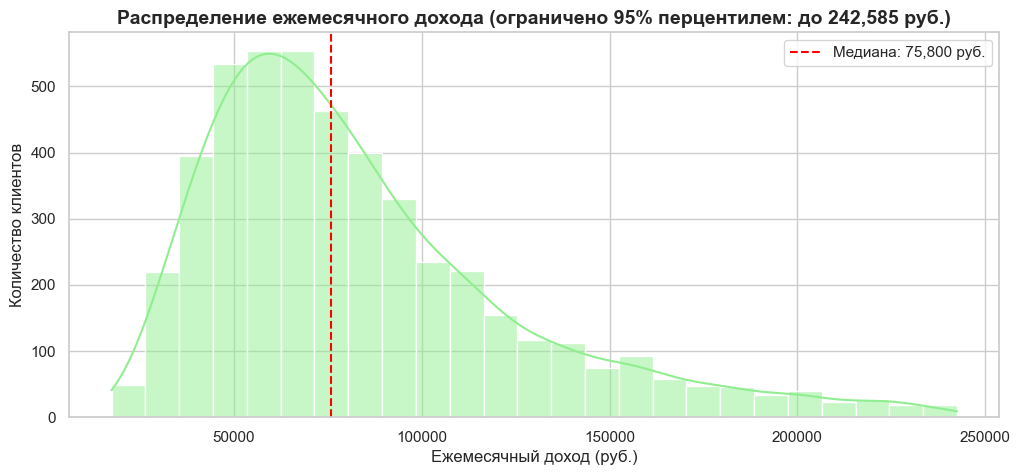

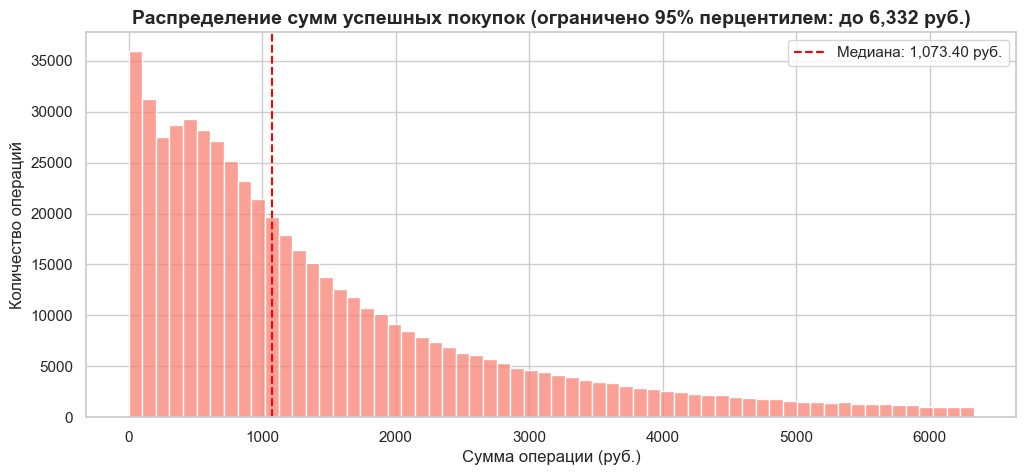

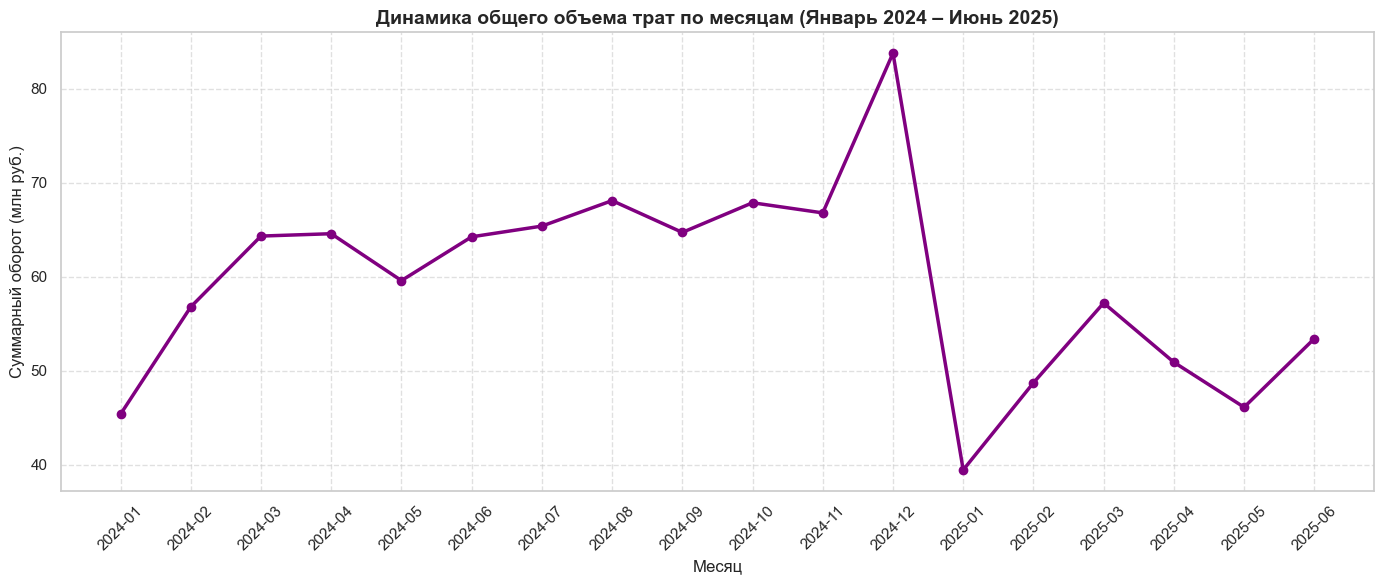


Динамика успешно построена! Обратите внимание на график 3: он наглядно покажет руководству, в каких именно месяцах начался спад активности.


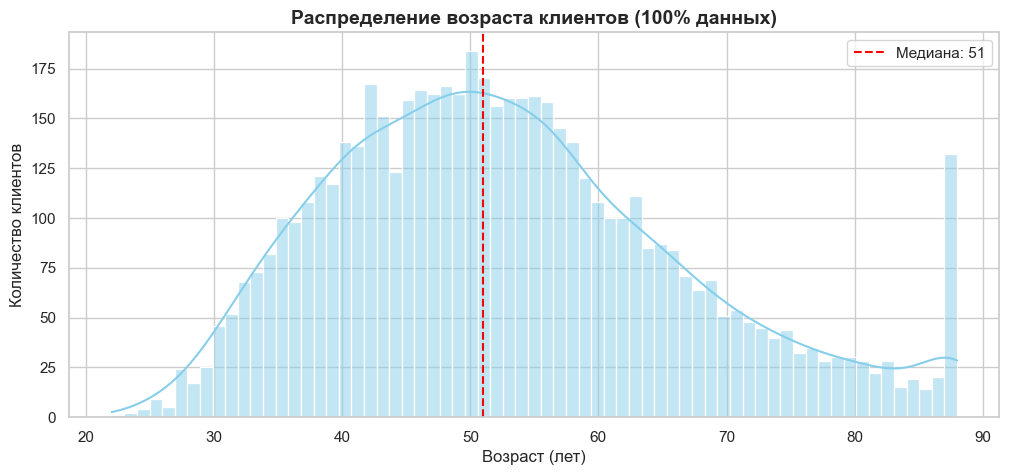

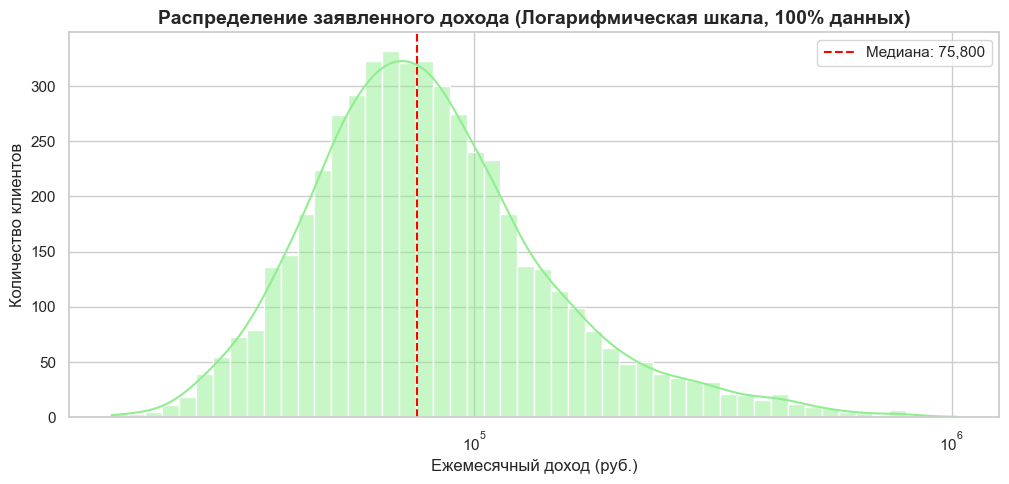

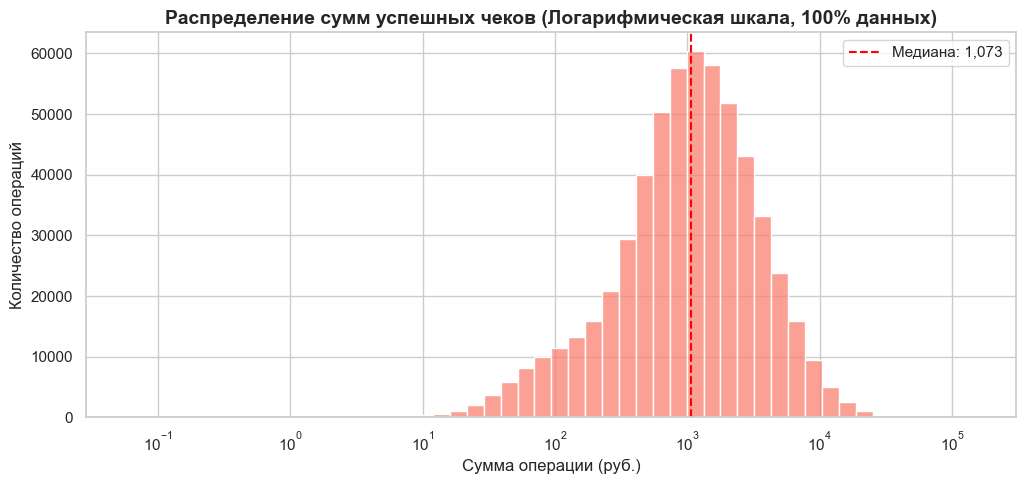

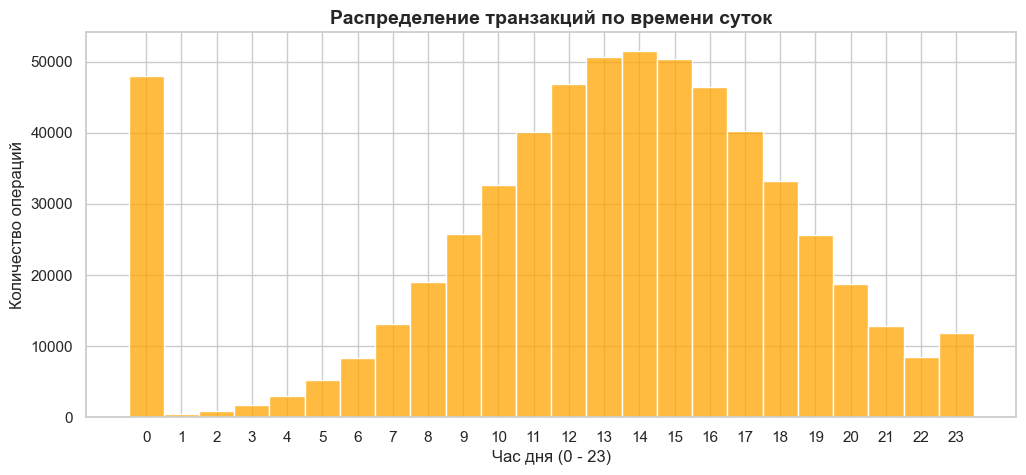


КРАТКАЯ СТАТИСТИКА:
Возраст: медиана = 51 лет, диапазон: 22 - 88
Доход: медиана = 75,800 руб., максимум = 1,026,300 руб.
Чеки: медиана = 1,073 руб., максимум = 147,058 руб.
=== АНАЛИЗ АНОМАЛИЙ: КЛИЕНТЫ 1937 Г.Р. И ТРАНЗАКЦИИ В 00:00 ===
Количество клиентов с годом рождения 1937: 82 из 5626 (1.46%)


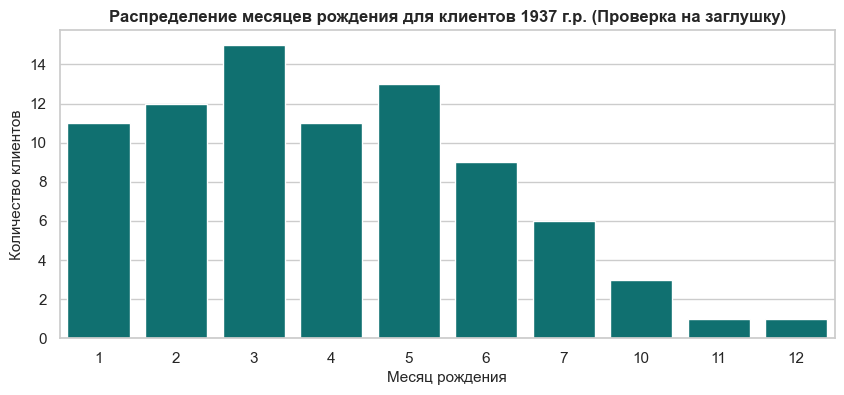


Топ-10 самых частых возрастов в базе клиентов:
{50.0: 184, 51.0: 170, 42.0: 167, 48.0: 166, 46.0: 164, 49.0: 162, 47.0: 162, 55.0: 161, 53.0: 160, 54.0: 160}
Строк без времени: 50255
Транзакций с часом '00:00' (полуночный пик / заглушки): 47,963 (8.06%)

Словарь распределения транзакций по часам суток (Час: Количество):
{0: 47963, 1: 464, 2: 917, 3: 1683, 4: 3057, 5: 5216, 6: 8336, 7: 13076, 8: 19041, 9: 25701, 10: 32607, 11: 40144, 12: 46838, 13: 50575, 14: 51542, 15: 50429, 16: 46449, 17: 40168, 18: 33225, 19: 25604, 20: 18679, 21: 12895, 22: 8482, 23: 11859}


In [ ]:
print("=" * 80)
print("=== 5.1. РАСПРЕДЕЛЕНИЯ КОЛИЧЕСТВЕННЫХ ПРИЗНАКОВ ===")
print("=" * 80)

sns.set_theme(style="whitegrid", palette="muted")

# 1. Подготовка данных
df_clients['age'] = (pd.to_datetime('2025-06-30') - df_clients['birth_date']).dt.days // 365.25
ages = df_clients['age'].dropna()

incomes = df_clients['monthly_income'].dropna()
amounts = df_txn_clean[(df_txn_clean['amount'] > 0) & (df_txn_clean['status'] != 'отклонено')]['amount']

# Извлекаем час совершения транзакции (от 0 до 23)
txn_hours = df_txn_clean['txn_datetime'].dt.hour.dropna()

print("=" * 80)
print("=== 5.1. РАСПРЕДЕЛЕНИЯ ДО 95-ГО ПЕРЦЕНТИЛЯ И ДИНАМИКА ПО ВРЕМЕНИ ===")
print("=" * 80)

sns.set_theme(style="whitegrid", palette="muted")

incomes = df_clients['monthly_income'].dropna()
amounts = df_txn_clean[(df_txn_clean['amount'] > 0) & (df_txn_clean['status'] != 'отклонено')]['amount']

# Границы 95-го перцентиля
inc_95 = incomes.quantile(0.95)
amt_95 = amounts.quantile(0.95)

incomes_95_data = incomes[incomes <= inc_95]
amounts_95_data = amounts[amounts <= amt_95]

# =======================================================
# ГРАФИК 1: ДОХОДЫ (до 95% квантиля)
# =======================================================
plt.figure(figsize=(12, 5))
sns.histplot(incomes_95_data, bins=25, kde=True, color='lightgreen')
plt.title(f'Распределение ежемесячного дохода (ограничено 95% перцентилем: до {inc_95:,.0f} руб.)', fontsize=14, fontweight='bold')
plt.xlabel('Ежемесячный доход (руб.)', fontsize=12)
plt.ylabel('Количество клиентов', fontsize=12)
plt.axvline(incomes.median(), color='red', linestyle='--', label=f'Медиана: {incomes.median():,.0f} руб.')
plt.legend()
plt.show()

# =======================================================
# ГРАФИК 2: СУММЫ ЧЕКОВ (до 95% квантиля)
# =======================================================
plt.figure(figsize=(12, 5))
sns.histplot(amounts_95_data, bins=62, kde=False, color='salmon')
plt.title(f'Распределение сумм успешных покупок (ограничено 95% перцентилем: до {amt_95:,.0f} руб.)', fontsize=14, fontweight='bold')
plt.xlabel('Сумма операции (руб.)', fontsize=12)
plt.ylabel('Количество операций', fontsize=12)
plt.axvline(amounts.median(), color='red', linestyle='--', label=f'Медиана: {amounts.median():,.2f} руб.')
plt.legend()
plt.show()

# =======================================================
# ГРАФИК 3: ДИНАМИКА ТРАНЗАКЦИЙ ПО МЕСЯЦАМ (Январь 2024 – Июнь 2025)
# =======================================================
# Создаем колонку с периодом "Год-Месяц"
df_txn_clean['year_month'] = df_txn_clean['txn_datetime'].dt.to_period('M')

# Группируем по месяцам (считаем общую сумму трат и количество транзакций)
monthly_dynamics = df_txn_clean[df_txn_clean['status'] != 'отклонено'].groupby('year_month').agg(
    total_amount=('amount', 'sum'),
    txn_count=('txn_id', 'count')
).reset_index()

# Переводим период обратно в строку/дату для красивого графика
monthly_dynamics['year_month_str'] = monthly_dynamics['year_month'].astype(str)

plt.figure(figsize=(14, 6))
plt.plot(monthly_dynamics['year_month_str'], monthly_dynamics['total_amount'] / 1e6, marker='o', color='purple', linewidth=2.5, markersize=6)
plt.title('Динамика общего объема трат по месяцам (Январь 2024 – Июнь 2025)', fontsize=14, fontweight='bold')
plt.xlabel('Месяц', fontsize=12)
plt.ylabel('Суммарный оборот (млн руб.)', fontsize=12)
plt.xticks(rotation=45)
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

print("\nДинамика успешно построена! Обратите внимание на график 3: он наглядно покажет руководству, в каких именно месяцах начался спад активности.")

# =======================================================
# ГРАФИК 1: ВОЗРАСТ (Обычная шкала)
# =======================================================
plt.figure(figsize=(12, 5))
sns.histplot(ages, bins=67, kde=True, color='skyblue')
plt.title('Распределение возраста клиентов (100% данных)', fontsize=14, fontweight='bold')
plt.xlabel('Возраст (лет)', fontsize=12)
plt.ylabel('Количество клиентов', fontsize=12)
plt.axvline(ages.median(), color='red', linestyle='--', label=f'Медиана: {ages.median():.0f}')
plt.legend()
plt.show()

# =======================================================
# ГРАФИК 2: ДОХОД (Логарифмическая шкала оси X)
# =======================================================
plt.figure(figsize=(12, 5))
# log_scale=True позволяет уместить и 20 тыс., и 1 млн на одном красивом графике
sns.histplot(incomes, bins=50, kde=True, color='lightgreen', log_scale=True)
plt.title('Распределение заявленного дохода (Логарифмическая шкала, 100% данных)', fontsize=14, fontweight='bold')
plt.xlabel('Ежемесячный доход (руб.)', fontsize=12)
plt.ylabel('Количество клиентов', fontsize=12)
plt.axvline(incomes.median(), color='red', linestyle='--', label=f'Медиана: {incomes.median():,.0f}')
plt.legend()
plt.show()

# =======================================================
# ГРАФИК 3: СУММЫ ТРАНЗАКЦИЙ (Логарифмическая шкала оси X)
# =======================================================
plt.figure(figsize=(12, 5))
sns.histplot(amounts, bins=50, kde=False, color='salmon', log_scale=True)
plt.title('Распределение сумм успешных чеков (Логарифмическая шкала, 100% данных)', fontsize=14, fontweight='bold')
plt.xlabel('Сумма операции (руб.)', fontsize=12)
plt.ylabel('Количество операций', fontsize=12)
plt.axvline(amounts.median(), color='red', linestyle='--', label=f'Медиана: {amounts.median():,.0f}')
plt.legend()
plt.show()

# =======================================================
# ГРАФИК 4: ВРЕМЯ ТРАНЗАКЦИЙ (Часы)
# =======================================================
plt.figure(figsize=(12, 5))
# discrete=True делает столбики ровно по целым часам
sns.histplot(txn_hours, bins=24, color='orange', discrete=True)
plt.title('Распределение транзакций по времени суток', fontsize=14, fontweight='bold')
plt.xlabel('Час дня (0 - 23)', fontsize=12)
plt.ylabel('Количество операций', fontsize=12)
plt.xticks(range(0, 24))
plt.show()

print("\nКРАТКАЯ СТАТИСТИКА:")
print(f"Возраст: медиана = {ages.median():.0f} лет, диапазон: {ages.min():.0f} - {ages.max():.0f}")
print(f"Доход: медиана = {incomes.median():,.0f} руб., максимум = {incomes.max():,.0f} руб.")
print(f"Чеки: медиана = {amounts.median():,.0f} руб., максимум = {amounts.max():,.0f} руб.")

print("=" * 80)
print("=== АНАЛИЗ АНОМАЛИЙ: КЛИЕНТЫ 1937 Г.Р. И ТРАНЗАКЦИИ В 00:00 ===")
print("=" * 80)

# =========================================================================
# 1. АНАЛИЗ КЛИЕНТОВ 1937 ГОДА РОЖДЕНИЯ (АРТЕФАКТ ВОЗРАСТА)
# =========================================================================
# Выделяем клиентов, родившихся в 1937 году (или чей возраст около 88 лет)
df_clients['birth_year'] = df_clients['birth_date'].dt.year
clients_1937 = df_clients[df_clients['birth_year'] == 1937].copy()

print(f"Количество клиентов с годом рождения 1937: {len(clients_1937)} из {len(df_clients)} ({len(clients_1937)/len(df_clients):.2%})")

# Строим график распределения по месяцам для тех, кто родился в 1937
clients_1937['birth_month'] = df_clients['birth_date'].dt.month
plt.figure(figsize=(10, 4))
sns.countplot(x='birth_month', data=clients_1937, color='teal')
plt.title('Распределение месяцев рождения для клиентов 1937 г.р. (Проверка на заглушку)', fontsize=12, fontweight='bold')
plt.xlabel('Месяц рождения', fontsize=11)
plt.ylabel('Количество клиентов', fontsize=11)
plt.show()

# Топ-10 самых частых возрастов в базе
print("\nТоп-10 самых частых возрастов в базе клиентов:")
print(df_clients['age'].value_counts().head(10).to_dict())


# =========================================================================
# 2. АНАЛИЗ ВРЕМЕНИ ТРАНЗАКЦИЙ И НУЛЕВЫХ ЧАСОВ (00:00)
# =========================================================================
# Выделяем часы
txn_hours_series = df_txn_clean['txn_datetime'].dt.hour

# Словарь: сколько транзакций пришлось на каждый час (0-23)
hours_dict = txn_hours_series.value_counts().sort_index().to_dict()

# Сколько именно транзакций упало ровно на 00 часов
zero_hour_count = hours_dict.get(0, 0)
total_txn_count = len(df_txn_clean)

print("Строк без времени:", (df_txn_raw['txn_datetime'].astype(str).str.len() == 10).sum())
print(f"Транзакций с часом '00:00' (полуночный пик): {zero_hour_count:,} ({zero_hour_count/total_txn_count:.2%})")

print("\nСловарь распределения транзакций по часам суток (Час: Количество):")
print(hours_dict)

### 5.2. Частотные характеристики категориальных признаков

### 5.3. Динамика по месяцам

### 5.4. Разрезы и связи между признаками

## 6. Метрика активности

Что именно вы считаете активностью, как она вычисляется, на каком
множестве клиентов, за какие окна. Отдельно: какое снижение эта метрика
**не увидит**.

## 7. Поиск и описание групп

Правило отбора для каждой группы, её размер, причина падения.
Правило разрешения конфликтов, если клиент подходит под несколько групп.

### 7.1. Кого в кампанию не берём и почему

## 8. Что проверили и что не подтвердилось

Гипотезы, которые вы проверили и отвергли. По одной строке на гипотезу,
с числом.

## 9. Сохранение результатов

Три файла: очищенная таблица для второго ноутбука, журнал изменений,
итоговый список кампании.

In [ ]:
# clean.to_parquet("clean_data.parquet", index=False)
# cleaning_log.to_csv("cleaning_log.csv", index=False, encoding="utf-8")
# campaign[["client_id", "group"]].to_csv("campaign_list.csv", index=False, encoding="utf-8")